# **Studi Kasus Klasifikasi Machine Learning**
## **Penerapan Algoritma Decision Tree untuk Klasifikasi Tumor Payudara**


---


### **1. Latar Belakang**
Machine Learning merupakan salah satu teknologi yang dapat digunakan untuk membantu menyelesaikan permasalahan klasifikasi. Salah satu penerapannya adalah klasifikasi tumor payudara berdasarkan karakteristik sel yang diperoleh dari pemeriksaan sampel jaringan.

Klasifikasi ini bertujuan untuk membedakan tumor jinak (*benign*) dan tumor ganas (*malignant*) berdasarkan sejumlah fitur numerik. Dalam studi kasus ini, algoritma Decision Tree digunakan untuk membangun model klasifikasi dan mengevaluasi kinerjanya.

### **2. Tujuan**
1. Memahami penerapan Machine Learning dalam permasalahan klasifikasi.
2. Membangun model klasifikasi menggunakan algoritma Decision Tree.
3. Mengevaluasi performa model menggunakan accuracy, precision, recall, F1-score, dan confusion matrix.

### **3. Dataset**
Dataset yang digunakan adalah Breast Cancer Wisconsin (Diagnostic) dari UCI Machine Learning Repository. Dataset ini terdiri atas 569 data, 30 fitur numerik, dan satu variabel target yang menunjukkan diagnosis tumor, yaitu jinak atau ganas.

**Sumber dataset:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

### **4. Metode**
Algoritma yang digunakan adalah Decision Tree Classifier. Data akan diperiksa terlebih dahulu, kemudian dibagi menjadi data latih sebesar 80% dan data uji sebesar 20%. Model dilatih menggunakan data latih dan dievaluasi menggunakan data uji.

### **5. Tahapan Penerapan**
1. Mengimpor library yang diperlukan.
2. Memuat dan memahami dataset.
3. Memeriksa kualitas data.
4. Membagi data menjadi data latih dan data uji.
5. Membangun model Decision Tree.
6. Melakukan prediksi dan evaluasi model.
7. Menarik kesimpulan berdasarkan hasil evaluasi.

### **6. Referensi**
Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B

**Import Library**

In [25]:

!pip install -q ucimlrepo

import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


**Mengambil dataset Breast Cancer Wisconsin**

In [26]:
dataset = fetch_ucirepo(id=17)

X = dataset.data.features.copy()
y = dataset.data.targets.iloc[:, 0].copy()

print("Dataset berhasil dimuat!")
print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("\nDistribusi target:")
print(y.value_counts())

Dataset berhasil dimuat!
Jumlah data: 569
Jumlah fitur: 30

Distribusi target:
Diagnosis
B    357
M    212
Name: count, dtype: int64


**Menampilkan 5 data pertama**

In [27]:
print("Lima data pertama:")
display(X.head())


Lima data pertama:


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Memeriksa ukuran dataset**

In [28]:
print("Ukuran dataset:", X.shape)

Ukuran dataset: (569, 30)


**Memeriksa data kosong**

In [29]:
print("\nJumlah data kosong:")
print(X.isnull().sum().sum())


Jumlah data kosong:
0


**Memeriksa data duplikat**

In [30]:
print("\nJumlah data duplikat:", X.duplicated().sum())


Jumlah data duplikat: 0


**Memeriksa tipe data**

In [31]:
print("\nTipe data:")
print(X.dtypes.value_counts())



Tipe data:
float64    30
Name: count, dtype: int64


**Visualisasi Distribusi Diagnosis**
#####Menghitung jumlah masing-masing diagnosis

In [32]:
diagnosis_counts = y.value_counts().sort_index()

Membuat grafik distribusi diagnosis

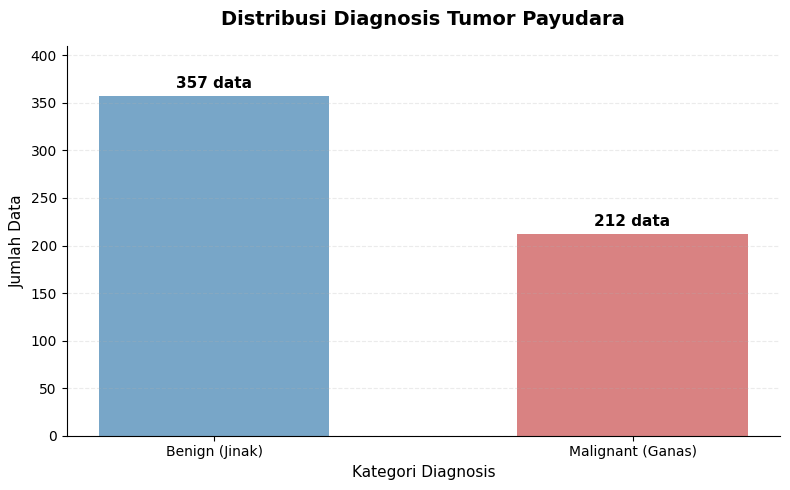

In [33]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    ["Benign (Jinak)", "Malignant (Ganas)"],
    diagnosis_counts.values,
    color=["#78A6C8", "#D98282"],
    width=0.55
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        f"{int(height)} data",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title("Distribusi Diagnosis Tumor Payudara",
          fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Kategori Diagnosis", fontsize=11)
plt.ylabel("Jumlah Data", fontsize=11)
plt.ylim(0, 410)
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


**Mengubah label diagnosis menjadi nama yang lebih mudah dipahami**

In [34]:
y = y.astype(str).str.strip().str.upper()
y = y.map({"B": "Benign (Jinak)", "M": "Malignant (Ganas)"})

**Membagi dataset menjadi data latih dan data uji**

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

print("\nDistribusi diagnosis pada data latih:")
print(y_train.value_counts())

print("\nDistribusi diagnosis pada data uji:")
print(y_test.value_counts())


Jumlah data latih: 455
Jumlah data uji: 114

Distribusi diagnosis pada data latih:
Diagnosis
Benign (Jinak)       285
Malignant (Ganas)    170
Name: count, dtype: int64

Distribusi diagnosis pada data uji:
Diagnosis
Benign (Jinak)       72
Malignant (Ganas)    42
Name: count, dtype: int64


**Membuat model Decision Tree**

In [36]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

**Melatih model menggunakan data latih**

In [37]:
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

**Melakukan prediksi pada data uji**

In [38]:
y_pred = model.predict(X_test)

print("Model Decision Tree berhasil dilatih!")
print("Jumlah prediksi:", len(y_pred))


Model Decision Tree berhasil dilatih!
Jumlah prediksi: 114


**Menghitung akurasi model**

In [39]:
accuracy = accuracy_score(y_test, y_pred)

print("Akurasi Model:", round(accuracy * 100, 2), "%")

Akurasi Model: 91.23 %


**Menampilkan precision, recall, dan F1-score**

In [40]:
print("\nLaporan Evaluasi Model:")
print(classification_report(y_test, y_pred, zero_division=0))



Laporan Evaluasi Model:
                   precision    recall  f1-score   support

   Benign (Jinak)       0.90      0.97      0.93        72
Malignant (Ganas)       0.94      0.81      0.87        42

         accuracy                           0.91       114
        macro avg       0.92      0.89      0.90       114
     weighted avg       0.91      0.91      0.91       114



**Membuat confusion matrix**

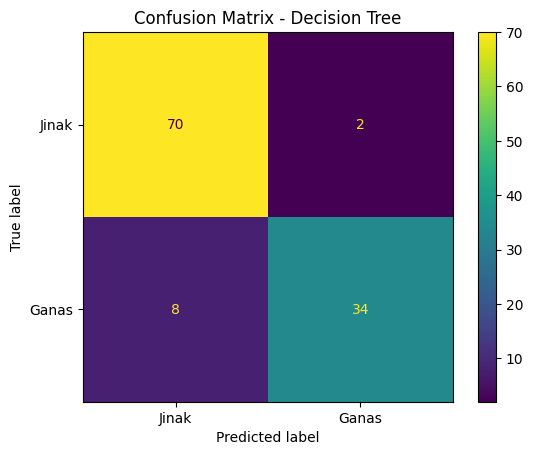

In [41]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Benign (Jinak)", "Malignant (Ganas)"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Jinak", "Ganas"]
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - Decision Tree")
plt.show()


**Visualisasi Tingkat Kepentingan Fitur**
#####Menghitung tingkat kepentingan setiap fitur

In [42]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)


Mengambil 10 fitur terpenting

In [43]:
top_features = feature_importance.head(10).sort_values()

Membuat grafik

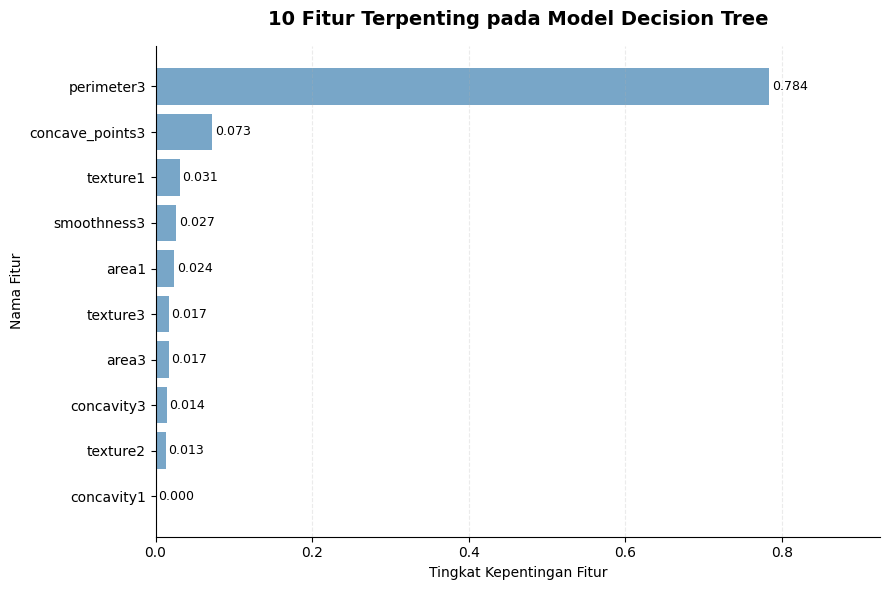

In [44]:
plt.figure(figsize=(9, 6))

bars = plt.barh(
    top_features.index,
    top_features.values,
    color="#78A6C8"
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va="center",
        fontsize=9
    )

plt.title(
    "10 Fitur Terpenting pada Model Decision Tree",
    fontsize=14,
    fontweight="bold",
    pad=15
)
plt.xlabel("Tingkat Kepentingan Fitur")
plt.ylabel("Nama Fitur")
plt.xlim(0, top_features.max() * 1.18)
plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


### **Visualisasi Tingkat Kepentingan Fitur**

Berdasarkan hasil analisis tingkat kepentingan fitur, `perimeter3` memiliki nilai tertinggi sebesar 0,784, diikuti oleh `concave_points3` sebesar 0,073 dan `texture1` sebesar 0,031. Hasil ini menunjukkan bahwa `perimeter3` merupakan fitur yang paling berpengaruh terhadap keputusan klasifikasi pada model Decision Tree yang dibangun.

Meskipun demikian, tingkat kepentingan fitur menggambarkan kontribusi relatif fitur dalam proses pengambilan keputusan model, bukan hubungan sebab-akibat secara langsung. Hasil ini juga bergantung pada struktur pohon keputusan dan data yang digunakan dalam pelatihan.

###**7. Hasil dan Pembahasan**

Berdasarkan pengujian menggunakan 114 data uji, model Decision Tree memperoleh akurasi sebesar 91,23%. Nilai precision untuk kelas tumor jinak sebesar 0,90 dan kelas tumor ganas sebesar 0,94. Sementara itu, recall masing-masing kelas sebesar 0,97 untuk tumor jinak dan 0,81 untuk tumor ganas.

Berdasarkan confusion matrix, model berhasil mengklasifikasikan 70 data tumor jinak dan 34 data tumor ganas dengan benar. Namun, terdapat 10 prediksi yang salah, terdiri atas 2 tumor jinak yang diprediksi sebagai ganas dan 8 tumor ganas yang diprediksi sebagai jinak.

Hasil tersebut menunjukkan bahwa algoritma Decision Tree dapat digunakan untuk mempelajari pola klasifikasi pada dataset yang digunakan. Akan tetapi, nilai recall kelas tumor ganas sebesar 0,81 menunjukkan bahwa model belum mampu mendeteksi seluruh kasus ganas secara tepat. Oleh karena itu, model ini masih perlu dievaluasi dan dikembangkan lebih lanjut sebelum dapat dipertimbangkan untuk penggunaan nyata.



###**8. Kesimpulan**

Algoritma Decision Tree berhasil diterapkan untuk mengklasifikasikan tumor payudara menjadi dua kategori, yaitu jinak dan ganas. Model memperoleh akurasi sebesar 91,23% pada data uji. Hasil ini menunjukkan potensi Machine Learning dalam membantu proses klasifikasi berdasarkan karakteristik data.

Meskipun demikian, model masih menghasilkan kesalahan klasifikasi, khususnya pada tumor ganas yang diprediksi sebagai jinak. Dengan demikian, model ini hanya digunakan untuk tujuan pembelajaran dan tidak dapat menggantikan pemeriksaan maupun diagnosis oleh tenaga medis.